## Crystals and Euphonic

In part 1 we used the Mantid GUI to compute INS spectra of powdered crystalline ethanol for TOSCA and MARI. This used approximations suitable for such systems which are dominated by incoherent scattering and have significant multi-phonon contributions.

In this tutorial we look more closely at dense inorganic systems and compute the coherent scattering cross section with different approximations. Our sample system is quartz, but again feel free to try others.

In [1]:
import ase.io
from ase.visualize import view
atoms = ase.io.read("structures/quartz.extxyz")
view(atoms, viewer="x3d")

Again we calculate the phonons with janus-core (and, under the hood, Phonopy) but this time we will process them with Euphonic.

In [38]:
%%bash
conda run -n ins-tutorial janus geomopt --struct structures/quartz.extxyz --arch mace_mp --model medium --fmax 1e-6 --optimizer LBFGS --opt-cell-fully --fix-symmetry

/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to 

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with /Users/adam.jackson/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.
       Step     Time          Energy          fmax
LBFGS:    0 16:07:33      -70.884722        0.812417
LBFGS:    1 16:07:33      -70.931162        0.690472
LBFGS:    2 16:07:33      -71.020457        0.190460
LBFGS:    3 16:07:33      -71.024261        0.168146
LBFGS:    4 16:07:33      -71.047930        0.139854
LBFGS:    5 16:07:33      -71.051200        0.110755
LBFGS:    6 16:07:33      -71.053784        0.111036
LBFGS:    7 16:07:33      -71.057242        0.128886
LBFGS:    8 16:07:33      -71.065031        0.151049
LBFGS:    9 16:07:33      -71.075577        0.193068
LBFGS:   10 16:07:34      -71.084994        0.181904
LBFGS:   11 16:07:34      -71.090543  

In [40]:
%%bash
conda run -n ins-tutorial janus phonons --struct=janus_results/quartz-opt.extxyz --arch=mace_mp --model=medium --supercell='2 2 2' --file-prefix='janus_results/quartz-222' --displacement 1e-3

/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to 

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with /Users/adam.jackson/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.

Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/9 -:--:--
Computing displacements... ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/9 -:--:--
Computing displacements... ━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/9 0:00:04
Computing displacements... ━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/9 0:00:03
Computing displacements... ━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 4/9 0:00:03
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━ 5/9 0:00:02
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━ 6/9 0:00:02
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━ 7/9 0:00:01
Computing displacements

and this time also try with a larger supercell:

In [41]:
%%bash
conda run -n ins-tutorial janus phonons --struct=janus_results/quartz-opt.extxyz --arch=mace_mp --model=medium --supercell='4 4 3' --file-prefix='janus_results/quartz-443' --displacement 1e-3

/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to 

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with /Users/adam.jackson/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.

Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/9 -:--:--
Computing displacements... ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/9 -:--:--
Computing displacements... ━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/9 0:00:20
Computing displacements... ━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/9 0:00:16
Computing displacements... ━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 4/9 0:00:13
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━ 5/9 0:00:11
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━ 6/9 0:00:08
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━ 7/9 0:00:06
Computing displacements

In [43]:
%%bash
conda run -n ins-tutorial janus phonons --struct=janus_results/quartz-opt.extxyz --arch=mace_mp --model=medium --supercell='5 5 3' --file-prefix='janus_results/quartz-553' --displacement 1e-3

/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/e3nn/o3/_wigner.py:10: UserWarning: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.join(os.path.dirname(__file__), 'constants.pt'))
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to 

cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with /Users/adam.jackson/.cache/mace/20231203mace128L1_epoch199model
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.

Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/9 -:--:--
Computing displacements... ━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/9 -:--:--
Computing displacements... ━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/9 0:00:36
Computing displacements... ━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/9 0:00:30
Computing displacements... ━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 4/9 0:00:24
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━━━ 5/9 0:00:20
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━ 6/9 0:00:15
Computing displacements... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━ 7/9 0:00:10
Computing displacements

First we inspect the band structure using some command-line tools:

In [45]:
%%!

conda run -n ins-tutorial euphonic-dispersion janus_results/quartz-222-phonopy.yml -s quartz_euphonic_222_bands.png --reorder
conda run -n ins-tutorial euphonic-dispersion janus_results/quartz-443-phonopy.yml -s quartz_euphonic_443_bands.png --reorder
conda run -n ins-tutorial euphonic-dispersion janus_results/quartz-553-phonopy.yml -s quartz_euphonic_553_bands.png --reorder

['Force constants not found in janus_results/quartz-222-phonopy.yml, attempting to read from janus_results/quartz-222-force_constants.hdf5',
 'ForceConstants data was loaded',
 'Getting band path...',
 'Computing phonon modes: 27 modes across 215 q-points',
 'Mapping modes to 1D band-structure',
 'Saved plot to /Users/adam.jackson/src/mdanse-2026-workshop/Notebooks/ins_simulations/quartz_euphonic_222_bands.png',
 '',
 'Force constants not found in janus_results/quartz-443-phonopy.yml, attempting to read from janus_results/quartz-443-force_constants.hdf5',
 'ForceConstants data was loaded',
 'Getting band path...',
 'Computing phonon modes: 27 modes across 215 q-points',
 'Mapping modes to 1D band-structure',
 'Saved plot to /Users/adam.jackson/src/mdanse-2026-workshop/Notebooks/ins_simulations/quartz_euphonic_443_bands.png',
 '',
 'Force constants not found in janus_results/quartz-553-phonopy.yml, attempting to read from janus_results/quartz-553-force_constants.hdf5',
 'ForceConstants 

We can see that some calculation features are quite sensitive to the supercell size.

**2x2x2 supercell**

![quartz_euphonic_bands.png](quartz_euphonic_222_bands.png)

**4x4x3 supercell**

![quartz_euphonic_bands.png](quartz_euphonic_443_bands.png)

**5x5x3 supercell**

![quartz_euphonic_bands.png](quartz_euphonic_553_bands.png)

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Question**

What do negative frequencies represent? Should we be worried?
</div>

## Phonon DOS analysis in Python

The `euphonic` library imports and represents the force constants as a python object which includes all the relevant data:

In [49]:
from euphonic import ForceConstants

fc_222 = ForceConstants.from_phonopy(summary_name="janus_results/quartz-222-phonopy.yml", fc_name="janus_results/quartz-222-force_constants.hdf5")
fc_443 = ForceConstants.from_phonopy(summary_name="janus_results/quartz-443-phonopy.yml", fc_name="janus_results/quartz-443-force_constants.hdf5")
fc_553 = ForceConstants.from_phonopy(summary_name="janus_results/quartz-553-phonopy.yml", fc_name="janus_results/quartz-553-force_constants.hdf5")

Force constants not found in janus_results/quartz-222-phonopy.yml, attempting to read from janus_results/quartz-222-force_constants.hdf5
Force constants not found in janus_results/quartz-443-phonopy.yml, attempting to read from janus_results/quartz-443-force_constants.hdf5
Force constants not found in janus_results/quartz-553-phonopy.yml, attempting to read from janus_results/quartz-553-force_constants.hdf5


In [48]:
print(fc_222.crystal.cell_vectors)
print(fc_222.crystal.atom_r[:2])  # first 2 atom positions
print(fc_222.sc_matrix)
print(fc_222.force_constants.shape)

[[2.5187233942336644 -4.362556889025039 0.0] [2.5187233942336653 4.362556889025039 0.0] [0.0 0.0 5.520936992098773]] angstrom
[[0.4155569  0.25314377 0.29684669]
 [0.74685623 0.16241312 0.96351335]]
[[2 0 0]
 [0 2 0]
 [0 0 2]]
(8, 27, 27)


<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Question**

Why does this force_constants array have these dimensions? 
</div>

A q-point sampling mesh is defined as a series of fractional coordinates in reciprocal space: Euphonic provides a utility to construct it from Monkorst--Pack specifications.

In [52]:
from euphonic.util import mp_grid

qpts = mp_grid([10, 10, 10])

The force constants are Fourier-interpolated on this mesh to form a set of phonon frequencies and eigenvectors:

In [65]:
phonon_modes = fc_553.calculate_qpoint_phonon_modes(qpts)
print(phonon_modes.frequencies[:5, 0])  # Lowest frequency at first 5 q-points
print()
print(phonon_modes.eigenvectors[0, 0])  # Eigenvector of lowest frequency at first q-point

[7.008477157354334 7.61312003203552 8.447781530980947 9.928928732565122 8.301344614420897] millielectron_volt

[[-0.0474737 +0.j          0.10139682-0.03884223j  0.24117573+0.03153807j]
 [ 0.03733227-0.10340438j -0.37898884+0.03450448j  0.06355082-0.15118954j]
 [-0.07578322+0.08577845j -0.03882172+0.02953507j  0.23948174-0.03241038j]
 [ 0.01549893-0.07806819j -0.40374532+0.07753927j  0.01551921-0.02208467j]
 [ 0.09580552-0.0245431j  -0.04598073+0.01029458j  0.22595303-0.10102841j]
 [ 0.07501036+0.09536805j  0.11318058+0.00951638j  0.23853475+0.02245289j]
 [-0.03501441+0.08061098j  0.28847   -0.12835694j  0.01696345+0.12360131j]
 [ 0.02452294+0.05970048j  0.29843438-0.04939325j -0.00936984+0.10334368j]
 [ 0.01590229+0.05082918j  0.03745176+0.00621689j  0.31632681-0.03126154j]]


<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Question**

Why are these eigenvectors complex numbers? 
</div>

We can flatten the data to a DOS and examine the convergence this way, with some broadening:

In [66]:
phonon_modes.frequencies.max()

Quantity(np.float64(144.6709286396522), "millielectron_volt")

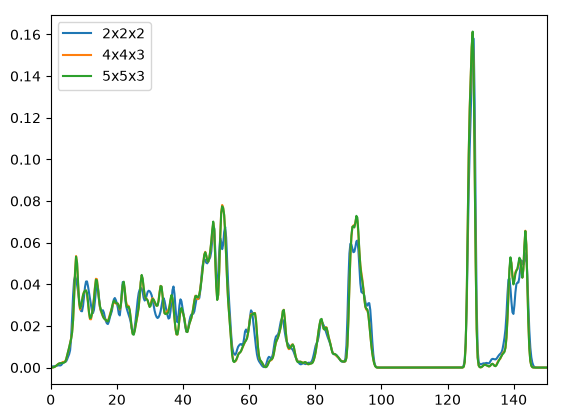

In [80]:
from euphonic import Quantity
from euphonic.plot import plot_1d
from euphonic.spectra import Spectrum1DCollection
import numpy as np
bins = Quantity(np.linspace(0, 150, 500), "meV")

spectra = []
for fc, label in [
    (fc_222, "2x2x2"),
    (fc_443, "4x4x3"),
    (fc_553, "5x5x3")
]:
    modes = fc.calculate_qpoint_phonon_modes(qpts)
    dos = modes.calculate_dos(bins)
    dos = dos.broaden(Quantity(1, "meV"))
    dos.metadata["label"] = label

    spectra.append(dos)

_ = plot_1d(Spectrum1DCollection.from_spectra(spectra))

We can see that there is not much movement from 4x4x3 to 5x5x3 supercell sampling.

## Coherent scattering simulations from the command-line

Single-crystal measurements on triple-axis spectrometers can directly probe the phonon band structure, but are still subject to instrumental broadening and neutron-scattering intensity effects. We can get a rough impression by computing the phonon band structure weighted by coherent scattering intensity and with some artificial broadening.

(The `--v-max` parameter controls the data range of the image, and generally needs to be tuned to avoid a single bright spot dominating.)

In [88]:
%%!
conda run -n ins-tutorial euphonic-intensity-map janus_results/quartz-553-phonopy.yml --weighting coherent --e-max 150 --energy-broadening 2 --q-broadening 0.2 --v-max 0.1 --save-to intensity_map.png

['/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/euphonic/spectra/base.py:1034: UserWarning: Invalid bin widths.',
 '',
 'Not all x-axis bins are the same width. Broadening by convolution may',
 'give incorrect results.',
 '',
 'Ensure x_data has regular spacing.',
 '  warnings.warn(str(e), UserWarning, stacklevel=1)',
 '/Users/adam.jackson/micromamba/envs/ins-tutorial/lib/python3.13/site-packages/euphonic/cli/intensity_map.py:91: UserWarning: x_data bin widths are not equal, so broadening by convolution may give',
 'incorrect results.',
 '  spectrum = spectrum.broaden(',
 '',
 'Force constants not found in janus_results/quartz-553-phonopy.yml, attempting to read from janus_results/quartz-553-force_constants.hdf5',
 'ForceConstants data was loaded',
 'Getting band path...',
 'Computing phonon modes: 27 modes across 214 q-points',
 'Computing intensities and generating 2D maps',
 'Plotting figure',
 'Found 3 regions in q-point path',
 'Saved plot to /Users

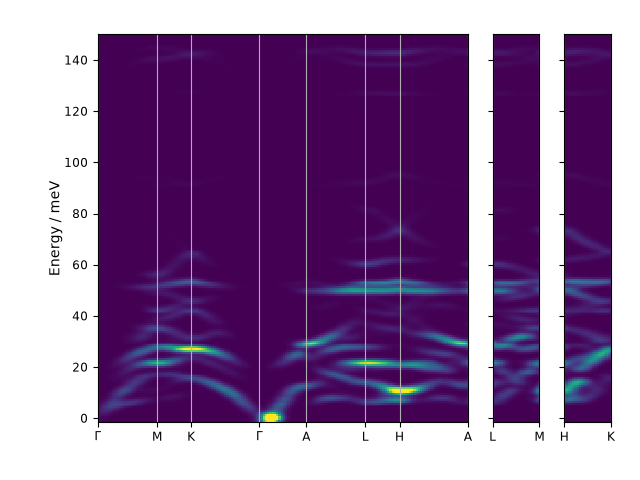

In [89]:
from IPython.display import Image
Image('intensity_map.png')

<div style="background-color:#fdf2e4;border-left:5px solid #c05621;border-radius:4px;padding:0.8em 1.2em;margin:0.6em 0;color:#1b1b1b">

**Question**

- Why is the intensity so low at Γ?
- How can that be avoided in a real triple-axis experiment?
- Why is intensity lower at higher frequencies?
</div>

We still see significant phonon dispersion at low energy, while the higher-energy branches have become weaker in intensity.

To simulate a powder sample on a chopper spectrometer such as MAPS, we need to apply numerical averaging and energy-Q ("kinematic") constraints.

In [92]:
%%!
conda run -n ins-tutorial euphonic-powder-map janus_results/quartz-553-phonopy.yml --weighting coherent --asr reciprocal --temperature 50 \
    --e-incident 60 --angle-range 3 60 --q-max 6 --e-max 50 \
    --energy-broadening 1 --q-broadening 0.05 --npts 500 --v-max 2 \
    --no-widgets --save-to powder_map.png

['',
 '100%|██████████| 240/240 [00:03<00:00, 62.06it/s]',
 '',
 'Force constants not found in janus_results/quartz-553-phonopy.yml, attempting to read from janus_results/quartz-553-force_constants.hdf5',
 'ForceConstants data was loaded',
 'Setting up dimensions...',
 'Calculating Debye-Waller factor on 15 x 15 x 12 q-point grid',
 'Sampling 240 |q| shells between 0.0 1/Å and 6.0 1/Å',
 'Final npts: 500',
 'Applying kinematic constraints',
 'Plotting figure: max intensity 18.994491022593778 mb/meV',
 'Saved plot to /Users/adam.jackson/src/mdanse-2026-workshop/Notebooks/ins_simulations/powder_map.png',
 '']

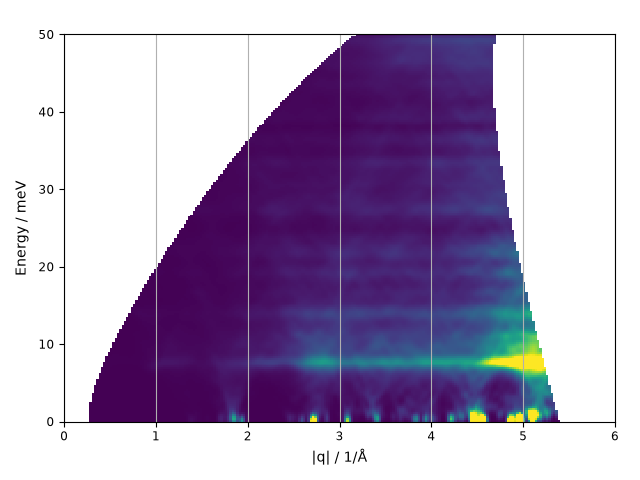

In [93]:
Image('powder_map.png')